In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("C:/Ruquayya Banu/Data Science/Datasets/data_1.csv",names = ["f1","y"])

In [4]:
df

,f1,y
0,-129.366669,28.000000
1,-130.282541,26.380447
2,-119.366669,12.000000
3,-111.659139,2.767886
4,-118.996509,-6.008839
...,...,...
94,115.182359,95.328786
95,128.409173,107.754816
96,131.633331,-114.000000
97,116.384601,-118.214869


In [5]:
df.describe()

,f1,y
count,99.000000,99.000000
mean,18.624101,-16.715312
std,84.660732,59.396962
min,-130.282541,-118.214869
25%,-63.228311,-64.352658
50%,24.203188,-34.000000
75%,105.460471,28.500000
max,132.633331,107.754816


In [6]:
# this dataset is in continues number - so regression algo need to use
# in linear regression algo - we need to use simple linear regression(SLR)
# we have very small data so we are considering entire dataset as training data

<Axes: xlabel='f1', ylabel='y'>

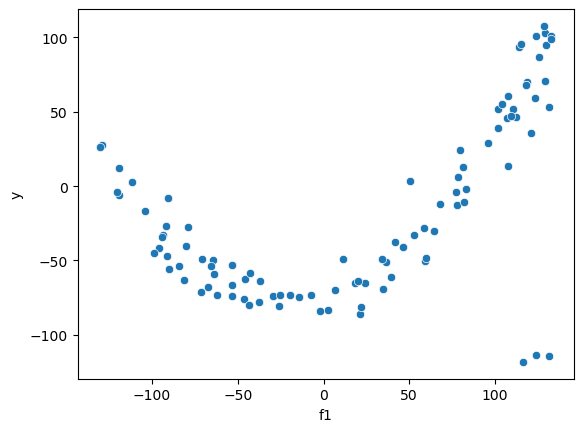

In [7]:
# visulaization:
sns.scatterplot(data = df, x = "f1", y="y")
# it has outliers also - 3 dots are in corner

In [8]:

# if you want to do train and test - here you need to splite the train and test data
# then per perform the linear regression on training data 
# and the predict the model on test data
#model training 
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(df[["f1"]],df[["y"]])

LinearRegression()

In [9]:
#finding intercept and slope
print(reg.coef_,reg.intercept_) 

[[0.38221563]] [-23.8337346]


In [10]:
# predicting - not splitting the data into training and test but directly applying algorithms
pred = reg.predict(df[["f1"]])
pred

array([[-73.27969793],
       [-73.62975845],
       [-69.45754159],
       [-66.51160316],
       [-69.31606065],
       [-69.80406971],
       [-63.72430707],
       [-59.56943119],
       [-58.45388337],
       [-59.04606691],
       [-59.90215073],
       [-54.3952281 ],
       [-53.92608622],
       [-60.42566907],
       [-56.07999439],
       [-48.57098672],
       [-58.64321459],
       [-61.64525532],
       [-54.93334749],
       [-49.65999553],
       [-51.02389814],
       [-58.25308302],
       [-51.11119114],
       [-48.32991708],
       [-44.15417253],
       [-48.84711469],
       [-47.67125044],
       [-41.25146107],
       [-41.49375854],
       [-40.51338225],
       [-44.23130973],
       [-44.28579284],
       [-40.21724254],
       [-37.89409878],
       [-35.05813451],
       [-38.31628661],
       [-33.65361695],
       [-33.47934697],
       [-26.64939055],
       [-22.85132792],
       [-31.3710336 ],
       [-29.27807588],
       [-21.29837167],
       [-14

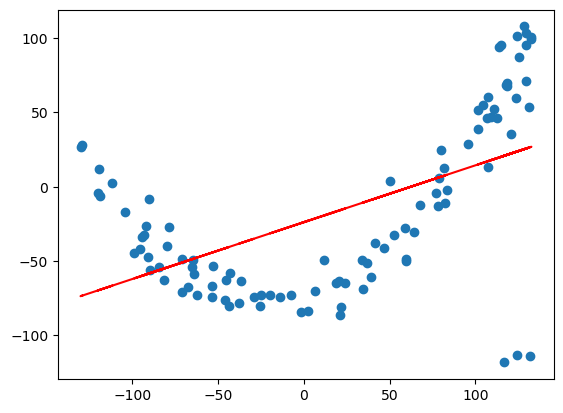

In [11]:
# if you do train and test - here you will see the visualization for train and test data
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred,"red") # line is showing that it is not best fit line 

In [12]:
# In the above scenario of underfitting if we try to use hyperparameter turning then it will be of no use as only the position of model will change but not the shape of the data.
# so until and unless the shape changes the model will never be able to capture the pattern in the data.
# in order to do so using linear regression we have to perform feature engineering.


In [13]:
# performing feature engineering to learn polynominal features

In [14]:
# fit transform for traning data and transform for test data - if we are following train and test data
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree = 2)
x_poly = poly_features.fit_transform(df[["f1"]])
x_poly # col-1 is 0degree # col2 is 1degree # col3 is 2degree
# anything with zero degree- then the result will always as 1
# anything with one degree- then result will always as is
# anything with two degree - then result will get it in square
# y= m1f1+m2f2+m3f3+c formula is used --> f is feature --> c is intercept

array([[ 1.00000000e+00, -1.29366669e+02,  1.67357350e+04],
       [ 1.00000000e+00, -1.30282541e+02,  1.69735404e+04],
       [ 1.00000000e+00, -1.19366669e+02,  1.42484016e+04],
       [ 1.00000000e+00, -1.11659139e+02,  1.24677633e+04],
       [ 1.00000000e+00, -1.18996509e+02,  1.41601691e+04],
       [ 1.00000000e+00, -1.20273299e+02,  1.44656664e+04],
       [ 1.00000000e+00, -1.04366669e+02,  1.08924015e+04],
       [ 1.00000000e+00, -9.34961665e+01,  8.74153316e+03],
       [ 1.00000000e+00, -9.05775318e+01,  8.20428927e+03],
       [ 1.00000000e+00, -9.21268759e+01,  8.48736126e+03],
       [ 1.00000000e+00, -9.43666687e+01,  8.90506816e+03],
       [ 1.00000000e+00, -7.99587739e+01,  6.39340553e+03],
       [ 1.00000000e+00, -7.87313467e+01,  6.19862495e+03],
       [ 1.00000000e+00, -9.57363624e+01,  9.16545108e+03],
       [ 1.00000000e+00, -8.43666687e+01,  7.11773479e+03],
       [ 1.00000000e+00, -6.47206705e+01,  4.18876519e+03],
       [ 1.00000000e+00, -9.10728836e+01

In [15]:
# tranforming x_poly array into dataframe
# both train and test data has to convert it into data frame
transform_df = pd.DataFrame(x_poly,columns= ["f1_0","f2_1","f3_2"])
transform_df["y"] = df["y"]
transform_df

,f1_0,f2_1,f3_2,y
0,1.0,-129.366669,16735.734971,28.000000
1,1.0,-130.282541,16973.540359,26.380447
2,1.0,-119.366669,14248.401597,12.000000
3,1.0,-111.659139,12467.763278,2.767886
4,1.0,-118.996509,14160.169083,-6.008839
...,...,...,...,...
94,1.0,115.182359,13266.975917,95.328786
95,1.0,128.409173,16488.915659,107.754816
96,1.0,131.633331,17327.333909,-114.000000
97,1.0,116.384601,13545.375303,-118.214869


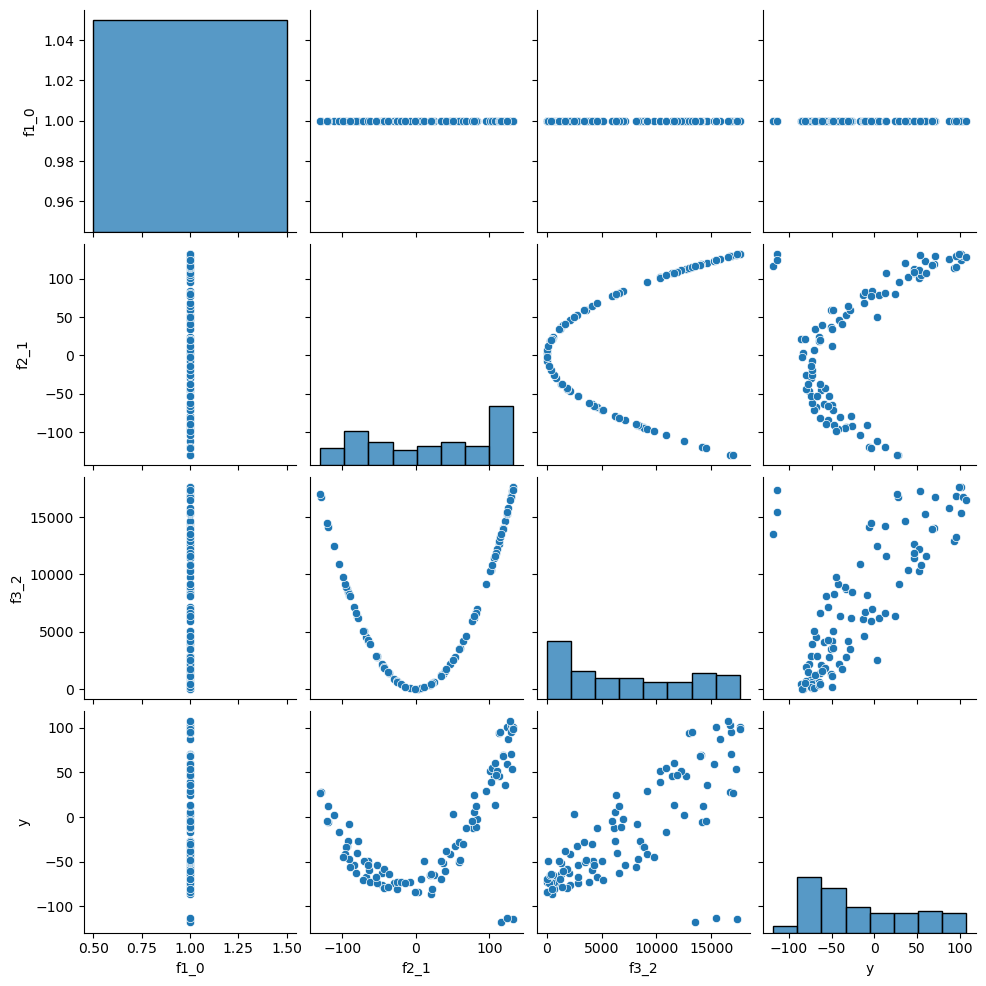

In [16]:
# plotting the graph for the transform_df
sns.pairplot(transform_df)

In [17]:
# f2 feature is showing the proper realtionship with y

In [18]:
reg_poly = LinearRegression()
reg_poly.fit(transform_df[["f1_0","f2_1","f3_2"]],transform_df["y"])

LinearRegression()

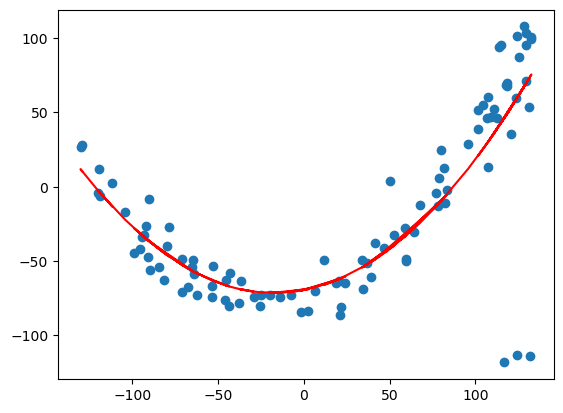

In [19]:
# prediction 
pred_poly = reg_poly.predict(transform_df[["f1_0","f2_1","f3_2"]])
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_poly,"red")


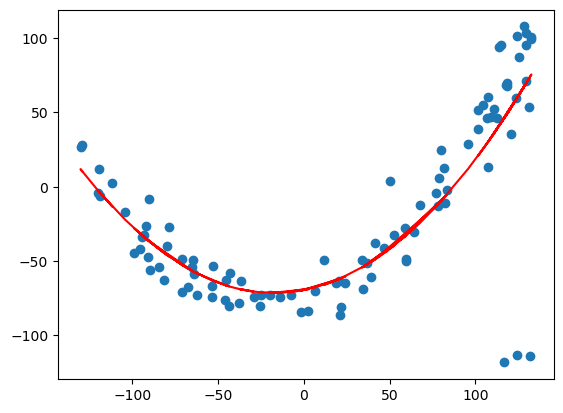

In [20]:
plt.scatter(df["f1"],df["y"])
plt.plot(df["f1"],pred_poly,"red")